# HW1 Part B: SIR simulation

Simulate over 160 days with $N = 2000$:

- $S(0) = 1995,\quad I(0) = 5,\quad R(0) = 0$
- $\beta = 0.125 \times 10^{-3}$ per person per day
- $\gamma = 0.1$ per day

Plot $S$, $I$ and $R$ over time and label each curve.


In [3]:
#part a code copied
import numpy as np

def forwardEuler(f, y0, t):
    # array of 0's to store inital value and all subsequent solved values
    y = np.zeros((len(t),) + np.shape(y0))
    # add initial condition to beginning of the array
    y[0] = y0
    # iterate over each time step
    for i in range(1, len(t)):
        #compute change in time 
        dt = t[i] - t[i-1]
        #previous time step solution plus time step change
        # multiplied by the derivative at the previous time step
        y[i] = y[i-1] + dt * f(y[i-1], t[i-1])
    return y


def sir_ders(y, beta, gamma):

    S, I, R = y
    dSdt = -beta * S * I
    dIdt = beta * S * I - gamma * I
    dRdt = gamma * I
    return np.array([dSdt, dIdt, dRdt])

def sir_model(y0, t, beta, gamma):
    def f(y, t):
        return sir_ders(y, beta, gamma)
    return forwardEuler(f, y0, t)

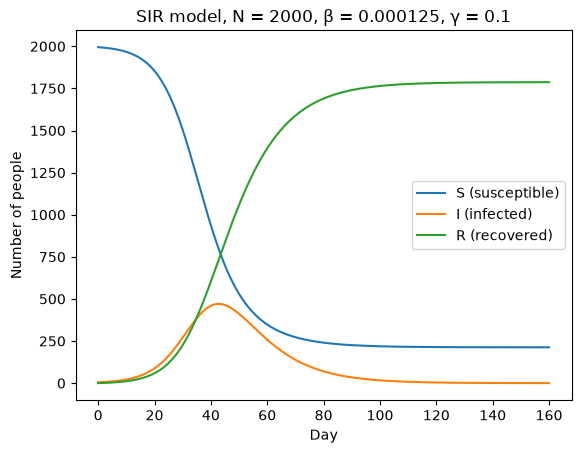

In [ ]:
import matplotlib.pyplot as plt

# intial conditions
N = 2000
S_0 = 1995
I_0 = 5
R_0 = 0
beta = 0.000125
gamma = 0.1

y0 = np.array([S_0, I_0, R_0])
# day 0 to day 160 with an euler step of 0.1 day 
t = np.arange(0, 160.1, 0.1)
solution = sir_model(y0, t, beta, gamma)
# transpose to get separate arrays 
S, I, R = solution.T

plt.plot(t, S, label='S (susceptible)')
plt.plot(t, I, label='I (infected)')
plt.plot(t, R, label='R (recovered)')
plt.xlabel('Day')
plt.ylabel('Number of people')
plt.title('SIR model, N = 2000, β = 0.000125, γ = 0.1')
plt.legend()
plt.savefig('partB_sir.png', dpi=150, bbox_inches='tight')
plt.show()